### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** auto-ARIMA for each sensor (temperature, humidity, VOC), with an ADF test, a 100-minute forecast, a backtest on the last 100 minutes, and residual plots.

**Data:** now reads `../data/sensors_1min.csv` (21,016 rows, 3–17 June). **The saved outputs come from the original run on the old `processed_data.csv`** (7,005 rows, 3–7 June), whose humidity column was misaligned in time. Re-running will give different numbers.

**Split:** hold out the last 100 minutes. **Horizon:** 100 minutes.

**Key result (saved output) vs baselines:**

| Sensor | auto-ARIMA order | RMSE / MAE | Best simple baseline (RMSE / MAE) |
|---|---|---|---|
| Temperature | (0,1,1) | 0.2636 / 0.2337 | train mean 0.1983 / 0.1676 |
| Humidity | (2,1,3) | 0.3024 / 0.2575 | last value 0.2990 / 0.2456 |
| VOC | (1,1,2) | 0.0440 / 0.0314 | train mean 0.0358 / 0.0296 (last value 0.0647) |

The baselines were computed later, during a review of the project. ARIMA does not beat the best simple baseline for any sensor; for VOC it only beats "repeat the last value".

**Caveats**
- The ARIMA order is chosen on the full series, including the 100 test minutes (mild leakage).
- In the saved run the humidity series is misaligned in time (old `processed_data.csv` bug), so the humidity result is not meaningful.
- One backtest window of 100 minutes is a very small test.
- `mean_squared_error(..., squared=False)` needs scikit-learn < 1.6.


##### CONTENTS: humidity, temp & voc Forecasting Trends

In [1]:
#pip install pandas matplotlib statsmodels pmdarima

In [2]:
# ==============================
# Data Handling and Visualization
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# Time Series Analysis Tools
# ==============================
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ==============================
# Automated ARIMA Model Selection
# ==============================
from pmdarima import auto_arima

# ==============================
# Model Evaluation Metrics
# ==============================
from sklearn.metrics import mean_squared_error, mean_absolute_error


In [3]:
# --- Load and Prepare Data ---
df = pd.read_csv('../data/sensors_1min.csv')
df['time'] = pd.to_datetime(df['time'], utc=True)
df.set_index('time', inplace=True)

In [5]:
# Downsample data to 1-minute frequency if not already done
df = df.resample('1min').mean()

def forecast_series(series, label='Variable'):
    series = series.dropna()

    # --- Stationarity Check: Augmented Dickey-Fuller Test ---
    result = adfuller(series)
    print(f"\nADF Test for {label}")
    print(f"ADF Statistic: {result[0]}")
    print(f"p-value: {result[1]}")
    for key, value in result[4].items():
        print(f"Critical Value {key}: {value}")

    # --- Fit Auto ARIMA Model ---
    print(f"\nFitting Auto ARIMA for {label}...")
    model = auto_arima(series, seasonal=False, trace=True,
                       error_action='ignore', suppress_warnings=True)
    print(model.summary())

    # --- Forecast Future Points ---
    n_periods = 100
    forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)
    last_index = series.index[-1]
    forecast_index = pd.date_range(start=last_index + pd.Timedelta(minutes=1),
                                   periods=n_periods, freq='1min')
    forecast_series = pd.Series(forecast, index=forecast_index)

    # --- Backtesting with Last n_periods Data (if enough data) ---
    if len(series) >= n_periods * 2:
        actual = series[-n_periods:]
        model.fit(series[:-n_periods])  # refit model without last n_periods
        pred, _ = model.predict(n_periods=n_periods, return_conf_int=True)
        rmse = mean_squared_error(actual, pred, squared=False)
        mae = mean_absolute_error(actual, pred)
        print(f"\nRMSE for {label}: {rmse:.4f}")
        print(f"MAE for {label}: {mae:.4f}")
    else:
        print("\nNot enough data for backtesting RMSE/MAE.")

    # --- Visualization ---

    # 1. Full Forecast Plot (Last 500 points + forecast)
    plt.figure(figsize=(15, 6))
    plt.plot(series[-500:], label=f'Observed {label}', color='blue')
    plt.plot(forecast_series, label=f'Forecast {label}', color='red')
    plt.fill_between(forecast_index, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3)
    plt.title(f"{label} Forecast using ARIMA")
    plt.xlabel("Time")
    plt.ylabel(label)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 2. Zoomed-in Plot: Recent Actual vs Forecast
    plt.figure(figsize=(15, 4))
    plt.plot(series[-200:], label='Recent Actual')
    plt.axvline(series.index[-1], color='black', linestyle='--', label='Forecast Start')
    plt.plot(forecast_series, label='Forecast', color='red')
    plt.title(f"{label} - Actual vs Forecast (Zoomed)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # 3. Residual Plot
    residuals = series - model.predict_in_sample()
    plt.figure(figsize=(12, 3))
    plt.plot(residuals, color='purple')
    plt.title(f"{label} - Residuals")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 4. Residuals Histogram with KDE
    plt.figure(figsize=(8, 4))
    sns.histplot(residuals.dropna(), kde=True, color='orange')
    plt.title(f"{label} - Residuals Distribution")
    plt.tight_layout()
    plt.show()

    # 5. Rolling Mean vs Forecast Plot
    plt.figure(figsize=(15, 4))
    plt.plot(series.rolling(window=30).mean(), label='Rolling Mean (30)', linestyle='--')
    plt.plot(series, alpha=0.3, label='Actual')
    plt.plot(forecast_series, label='Forecast', color='red')
    plt.title(f"{label} - Rolling Mean vs Forecast")
    plt.legend()
    plt.grid(True)
    plt.show()



ADF Test for Temperature
ADF Statistic: -4.378275934057779
p-value: 0.0003242416205509493
Critical Value 1%: -3.431288013847613
Critical Value 5%: -2.8619545265178346
Critical Value 10%: -2.5669906485204703

Fitting Auto ARIMA for Temperature...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-32662.094, Time=13.66 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-32213.613, Time=1.90 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-32634.927, Time=1.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-32666.485, Time=4.02 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-32215.607, Time=0.54 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-32664.790, Time=4.08 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-32664.754, Time=5.32 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-32662.626, Time=10.21 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=-32668.440, Time=0.87 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=-32666.538, Time=1.46 sec
 ARIMA(0,1,2)(0,0,0)[0]     

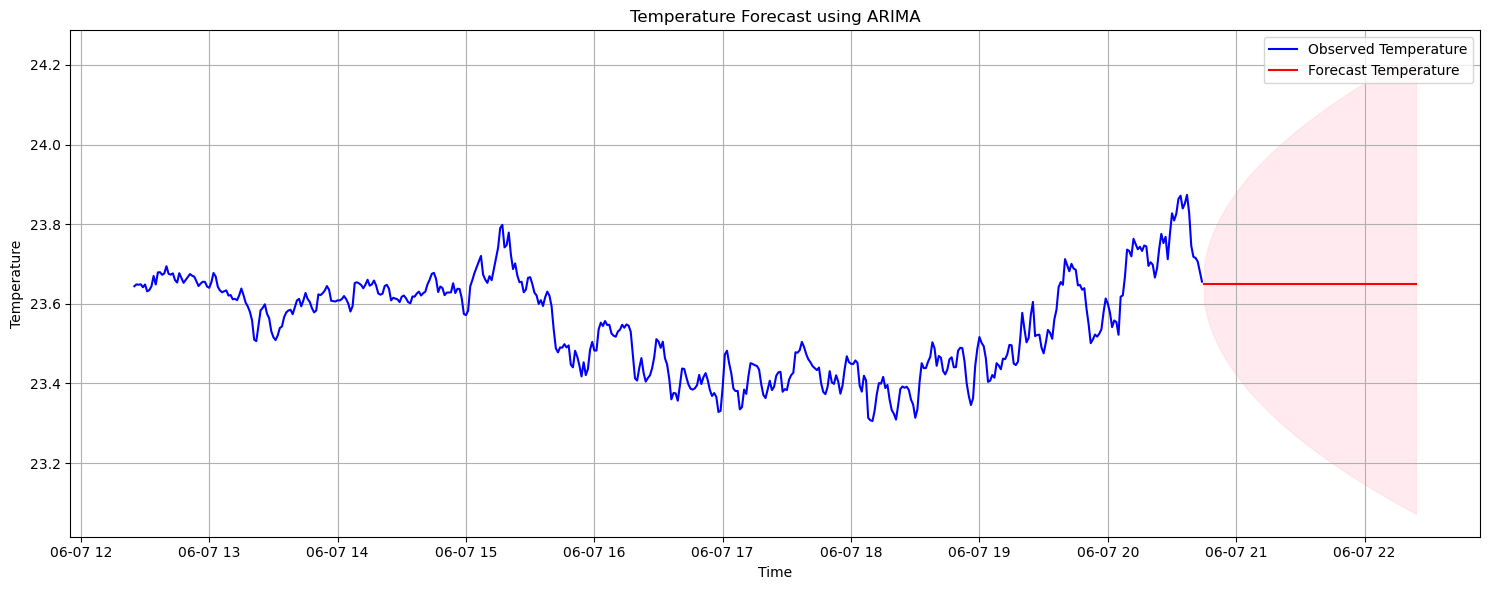

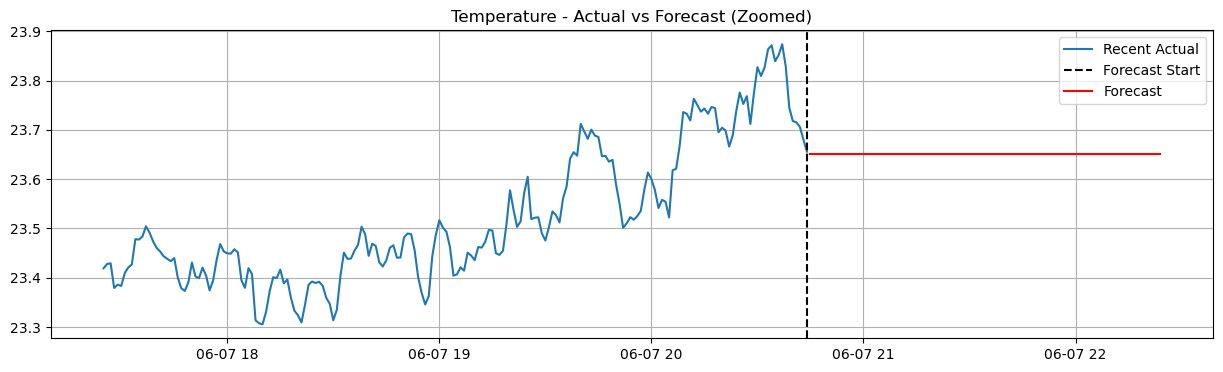

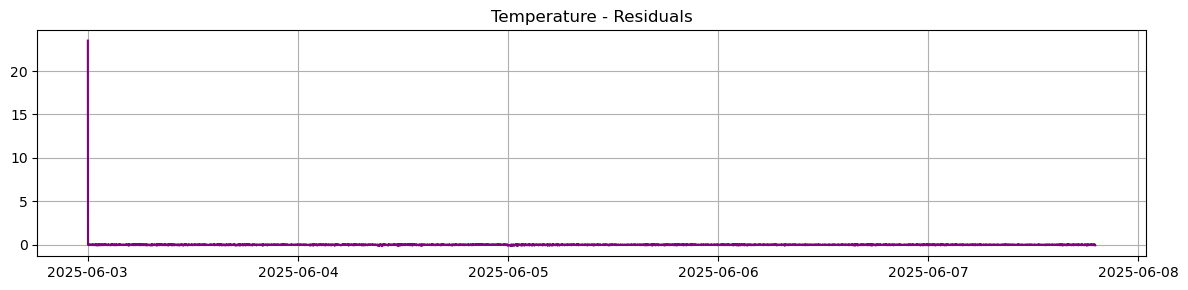

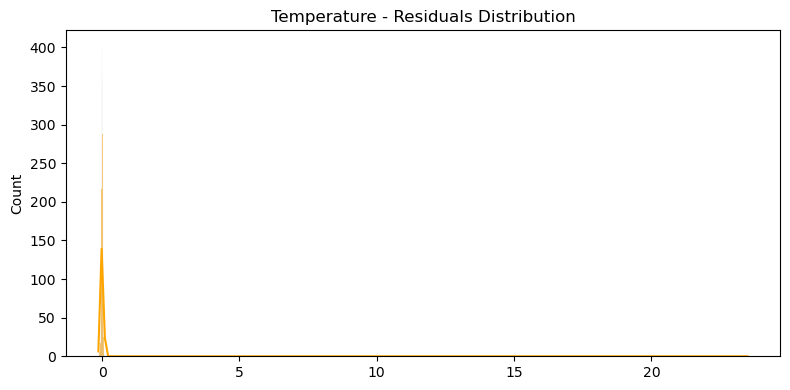

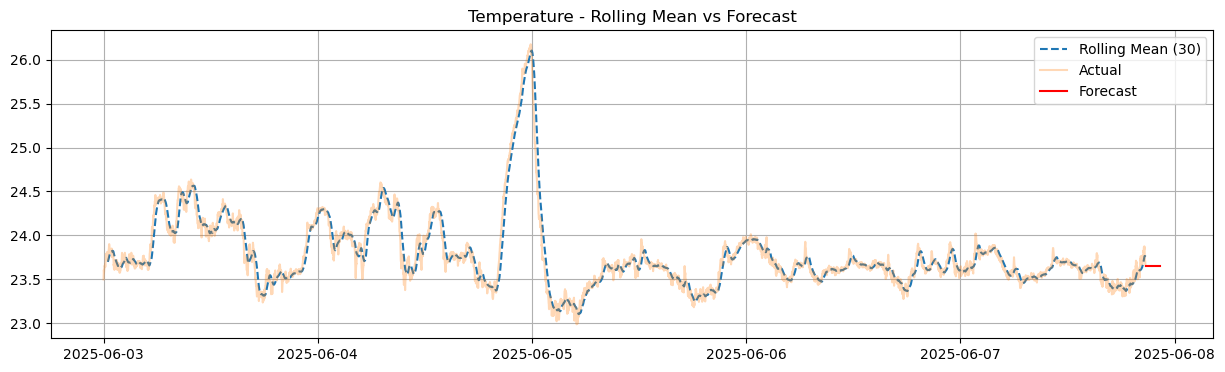

In [6]:
forecast_series(df['temperature'], label='Temperature') # Run forecasting and diagnostics for each variable


ADF Test for Humidity
ADF Statistic: -4.898577259099943
p-value: 3.509742559274855e-05
Critical Value 1%: -3.4312870729346066
Critical Value 5%: -2.8619541107756716
Critical Value 10%: -2.566990427213563

Fitting Auto ARIMA for Humidity...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-11717.662, Time=13.08 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-9245.485, Time=1.29 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-11417.513, Time=0.83 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-10718.303, Time=1.82 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-9247.474, Time=0.52 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-11716.058, Time=7.71 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-11719.660, Time=10.28 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-11676.299, Time=4.19 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=-11588.534, Time=1.06 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=-11717.663, Time=8.91 sec
 ARIMA(3,1,0)(0,0,0)[0] intercept   

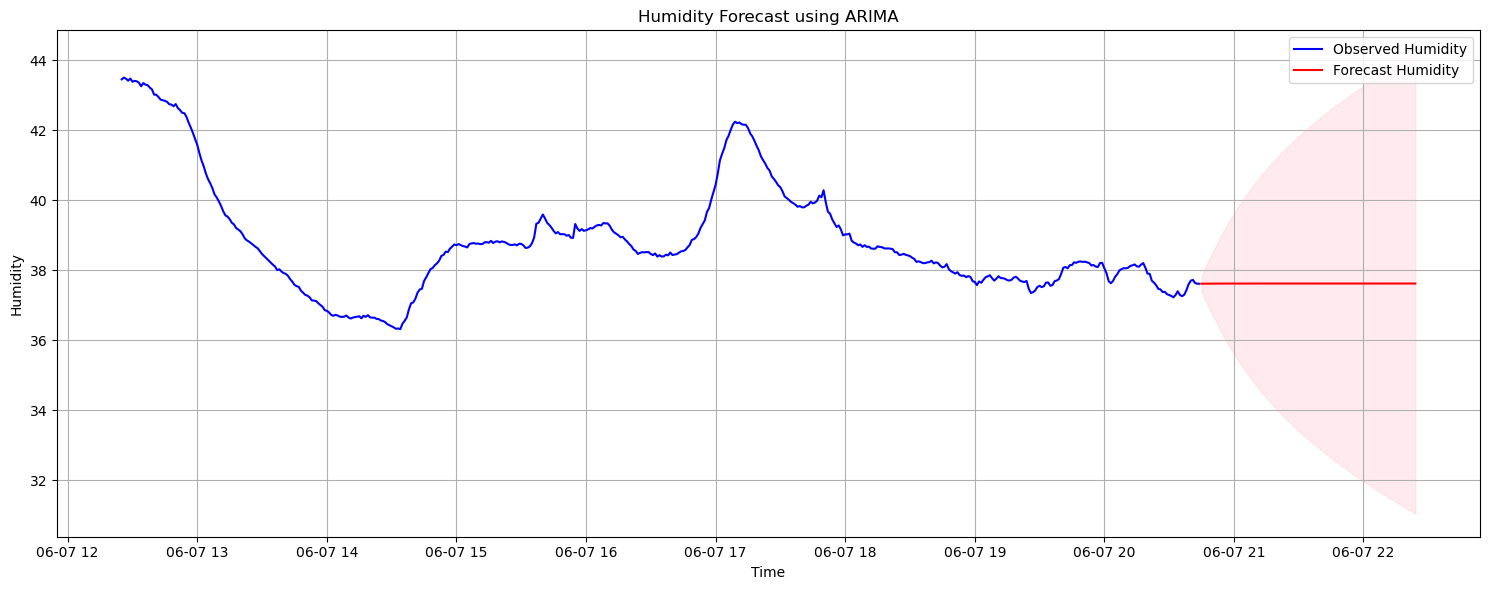

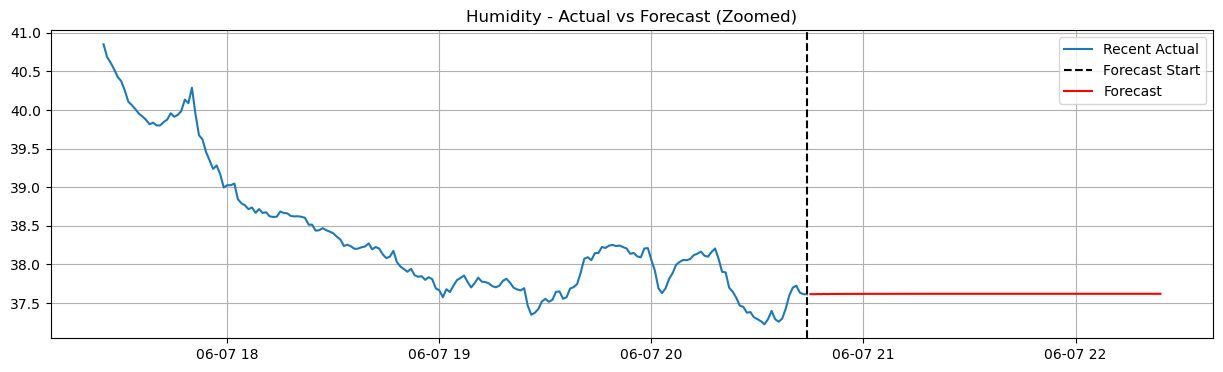

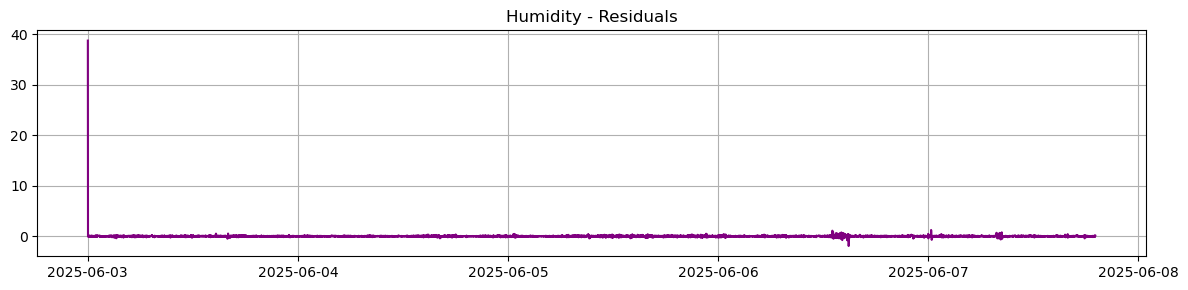

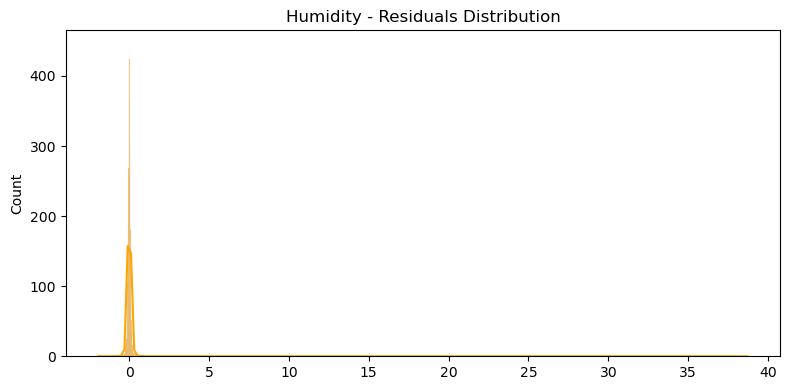

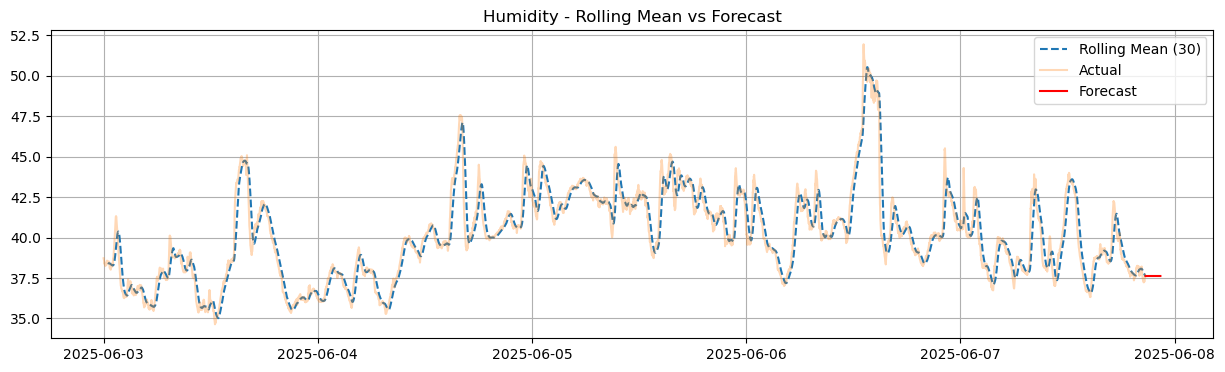

In [7]:
forecast_series(df['humidity'], label='Humidity') # Run forecasting and diagnostics for each variable


ADF Test for VOC
ADF Statistic: -5.199021985037093
p-value: 8.832595412787984e-06
Critical Value 1%: -3.431286133907351
Critical Value 5%: -2.861953695866596
Critical Value 10%: -2.566990206350145

Fitting Auto ARIMA for VOC...
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-27404.609, Time=12.67 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-25675.075, Time=1.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-26493.273, Time=0.81 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-27213.314, Time=3.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=-25677.074, Time=0.43 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=-27405.596, Time=19.36 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=-27404.749, Time=7.44 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=-27402.600, Time=3.55 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=-27400.877, Time=10.36 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=-27404.835, Time=4.37 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=-27

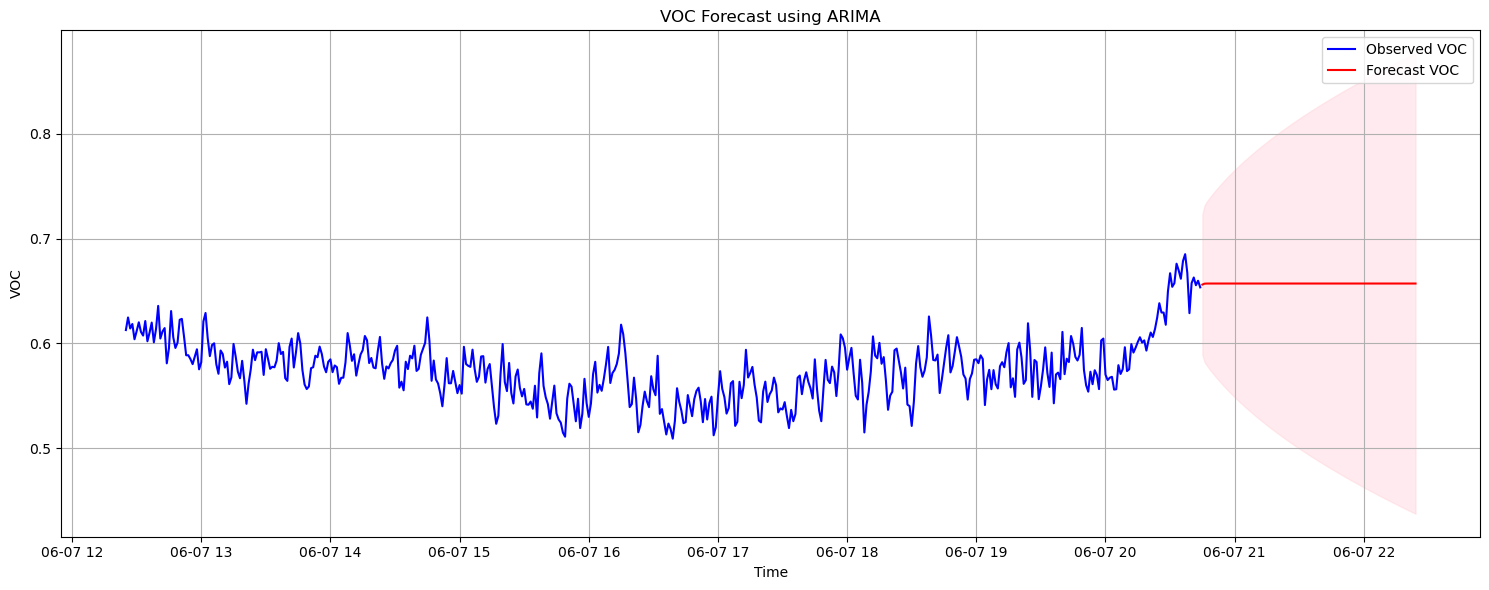

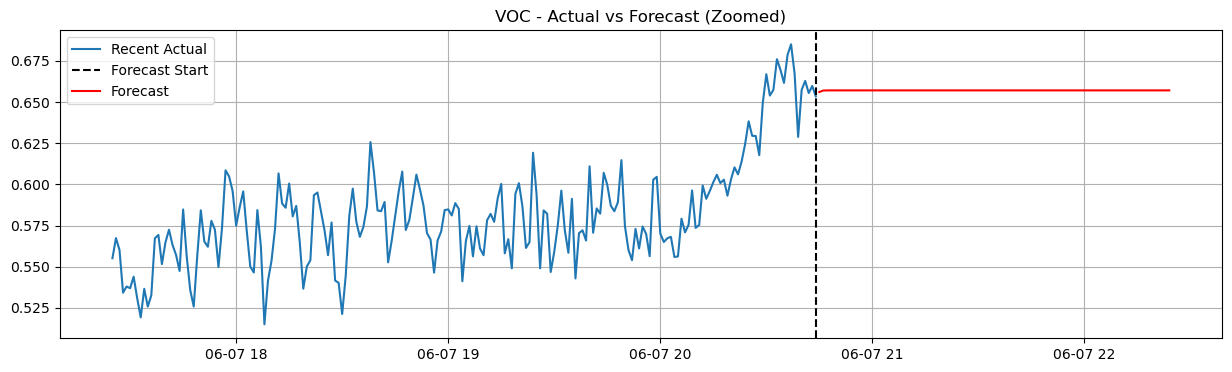

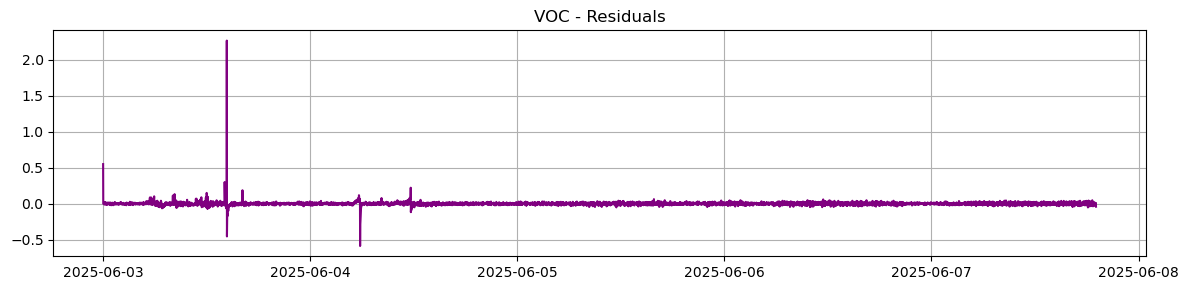

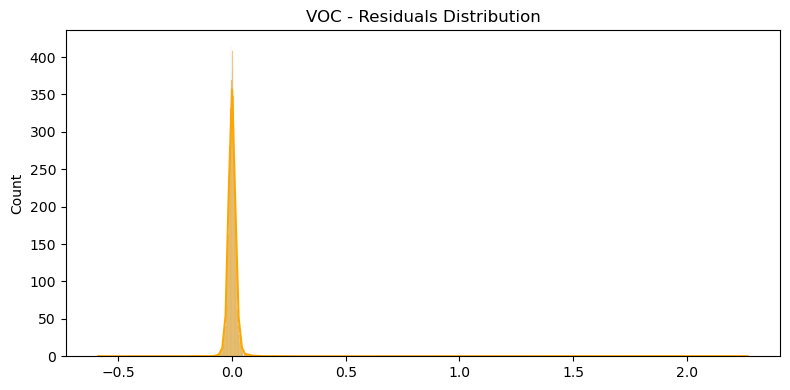

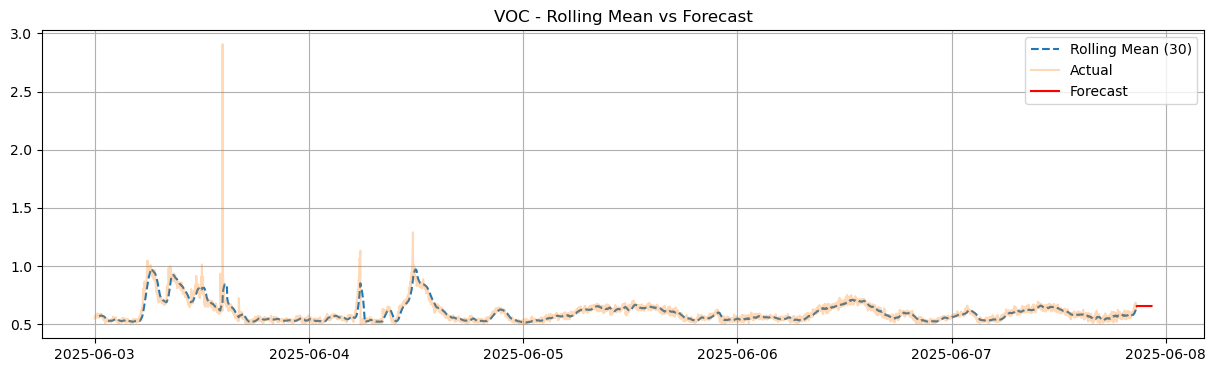

In [8]:
forecast_series(df['VOC'], label='VOC') # Run forecasting and diagnostics for each variable